In [1]:
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
from scipy.stats import bootstrap
import numpy as np

In [2]:
data = pd.read_csv("results/rho_evaluation.csv")

In [3]:
rhos = [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0, 1.05, 1.1, 1.15, 1.2, 1.25, 1.3, 1.35, 1.4, 1.45, 1.5]

In [4]:
costs = [((data[f'Rho={rho}-random'].median() - data[f'Rho={rho}-optimal'].median()) / data[f'Rho={rho}-random'].median()) * 100 for rho in rhos]

In [5]:
def get_med_ci(data, base_case):
    median = ((base_case - data.median()) / base_case) * 100
    res = bootstrap(
        (((base_case - data) / base_case) * 100,), np.median, axis=0, confidence_level=0.95, n_resamples=10000
    )
    ci_low, ci_high = res.confidence_interval
    return median, median - ci_low, ci_high - median

In [6]:
medians = []
yerrs = [[], []]
for rho in rhos:
    base_case = data[f'Rho={rho}-random'].median()
    m, l, u = get_med_ci(data[f'Rho={rho}-optimal'], base_case)
    medians.append(m)
    yerrs[0].append(l)
    yerrs[1].append(u)

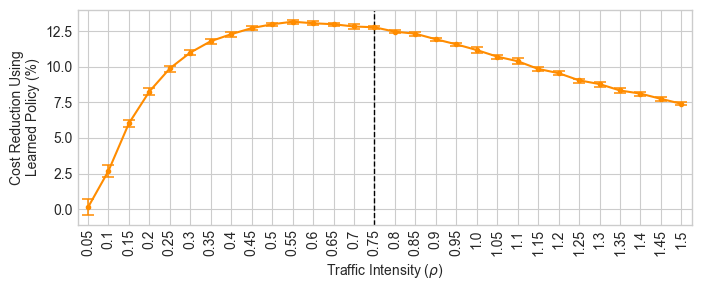

In [7]:
fig, ax = plt.subplots(1, figsize=(7, 3))
ax.errorbar(
    rhos, medians, yerr=yerrs,
    fmt='-o', capsize=4, capthick=1.1, elinewidth=1.1, c='darkorange', markersize=3
)
ax.axvline(x=0.75, color='black', linestyle='--', linewidth=1.0)
ax.set_xticks(rhos)
ax.set_xticklabels(rhos, rotation=90)
ax.set_xlim(0.025, 1.525)
ax.set_xlabel(r"Traffic Intensity ($\rho$)")
ax.set_ylabel("Cost Reduction Using\nLearned Policy (%)")
plt.tight_layout()
fig.savefig("../../../plt/vary_rho_experiment.pdf")